# 01 - Exploratory & Descriptive Analytics
**Goal:** understand the real pharmacy sales data before modelling: quality, trend, seasonality, product mix,
and how stable each therapeutic class is (ABC-XYZ).

> Data: Kaggle *Pharma Sales Data* (real, not synthetic): quantities per ATC class. Prices used for revenue are
> **assumptions** from `config.yaml` because the data has no price column.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import load_config, results_dir

cfg = load_config()
RES, FIG = results_dir(cfg), ROOT / cfg["paths"]["figures_dir"]
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

## 1. Ingestion, validation and cleaning
`src/data/ingest.py` validates the schema, removes duplicates, completes the calendar, imputes gaps and winsorises only *extreme* outliers. The quality report is saved as JSON.

In [2]:
import json

dq = json.loads((RES / "data_quality_report.json").read_text())
pd.Series({k: v for k, v in dq.items() if not isinstance(v, (dict, list))}).to_frame("value")

,value
rows_loaded,16848
unparseable_dates,0
exact_duplicate_rows_removed,0
duplicate_key_rows_aggregated,0
calendar_days_missing_before_fill,0
missing_values_imputed,0
negative_values_set_missing_then_imputed,0
hourly_rows,404256
is_synthetic,False


In [3]:
pd.DataFrame({k: dq[k] for k in ["outliers_capped_by_category", "zero_sales_day_share"]})

,outliers_capped_by_category,zero_sales_day_share
M01AB,0,0.02
M01AE,0,0.02
N02BA,0,0.04
N02BE,0,0.01
N05B,1,0.02
N05C,6,0.68
R03,0,0.23
R06,0,0.12


`units_raw` vs `units` shows exactly what the cleaning changed:

In [4]:
from src.data.store import read_daily

daily = read_daily(cfg)
chg = daily[daily.units != daily.units_raw]
print(f"{len(chg)} of {len(daily):,} rows changed by outlier capping")
chg[["date", "category", "units_raw", "units"]].head(10)

7 of 16,848 rows changed by outlier capping


,date,category,units_raw,units
9437,2016-10-11,N05B,54.83,37.07
11406,2016-05-27,N05C,7.00,6.20
11439,2016-06-29,N05C,7.00,6.20
11756,2017-05-12,N05C,9.00,6.20
12047,2018-02-27,N05C,9.00,6.20
12054,2018-03-06,N05C,8.00,6.20
12078,2018-03-30,N05C,8.00,6.20


## 2. KPIs

In [5]:
from src.analytics.descriptive import kpis

k = kpis(daily)
print({a: (round(b, 2) if isinstance(b, float) else b) for a, b in k.items() if a != "top_categories"})
k["top_categories"]

{'total_revenue': 5155259.72, 'total_units': 127566.97, 'avg_daily_units': 60.57, 'mom_growth_pct': 7.92, 'yoy_growth_pct': -17.34, 'last_complete_month': Timestamp('2019-09-01 00:00:00'), 'n_days': 2106}


,units,revenue
category,,
R03,"11,608.82","1,625,235.21"
N02BE,"63,005.40","1,134,097.25"
N05B,"18,627.98","1,117,678.68"


## 3. Trend and category mix

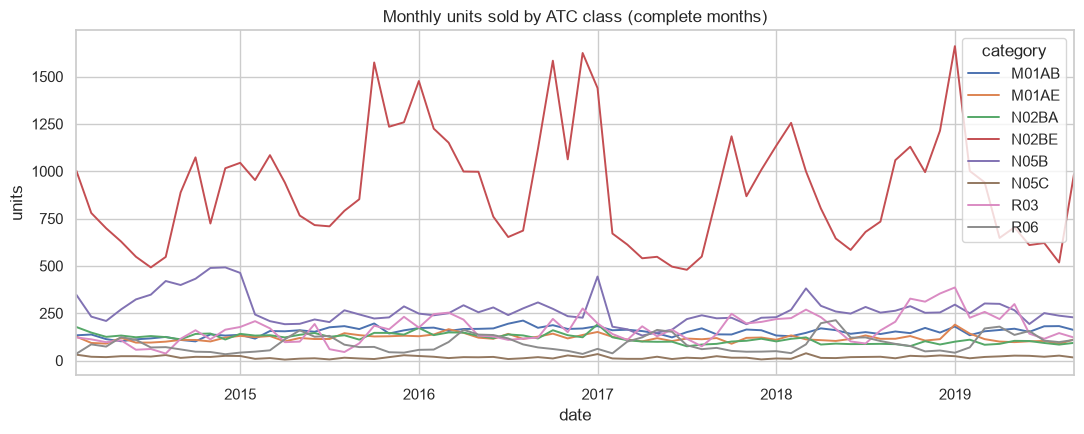

In [6]:
piv = daily.pivot(index="date", columns="category", values="units")
m = piv.resample("MS").sum().iloc[1:-1]
m.plot(figsize=(11, 4.5), lw=1.4, title="Monthly units sold by ATC class (complete months)")
plt.ylabel("units"); savefig("eda_monthly_units")

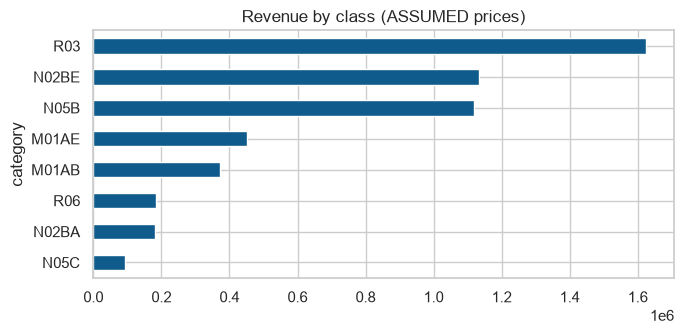

In [7]:
share = daily.groupby("category")["revenue"].sum().sort_values()
share.plot.barh(figsize=(7, 3.5), color="#0F5C8C", title="Revenue by class (ASSUMED prices)")
savefig("eda_revenue_share")

## 4. Seasonality: STL decomposition
STL (Cleveland et al., 1990) separates trend, seasonal and remainder. Weekly cycle on daily data; annual cycle on weekly totals.

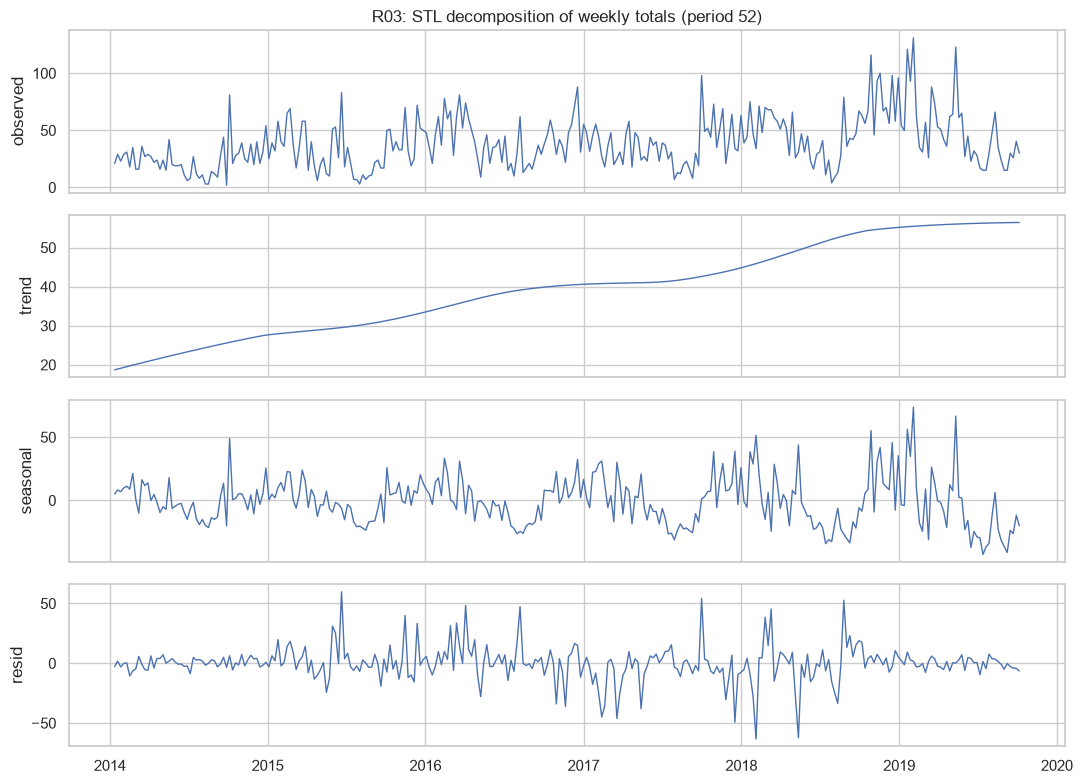

In [8]:
from src.analytics.descriptive import seasonal_strength, stl_decompose

cat = "R03"
y = piv[cat]
res = stl_decompose(y.resample("W").sum().iloc[1:-1], 52)
fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for a, (n, s) in zip(ax, [("observed", res.observed), ("trend", res.trend), ("seasonal", res.seasonal), ("resid", res.resid)]):
    a.plot(s, lw=1); a.set_ylabel(n)
ax[0].set_title(f"{cat}: STL decomposition of weekly totals (period 52)")
savefig("eda_stl_R03")

In [9]:
strength = pd.DataFrame({
    "weekly_cycle": {c: seasonal_strength(piv[c], 7) for c in piv},
    "annual_cycle": {c: seasonal_strength(piv[c].resample("W").sum().iloc[1:-1], 52) for c in piv}})
strength.sort_values("annual_cycle", ascending=False)

,weekly_cycle,annual_cycle
R06,0.14,0.74
N02BE,0.23,0.71
R03,0.11,0.52
N02BA,0.22,0.40
N05B,0.23,0.37
M01AE,0.21,0.32
M01AB,0.22,0.26
N05C,0.05,0.17


### Weekday x month and weekday x hour heatmaps

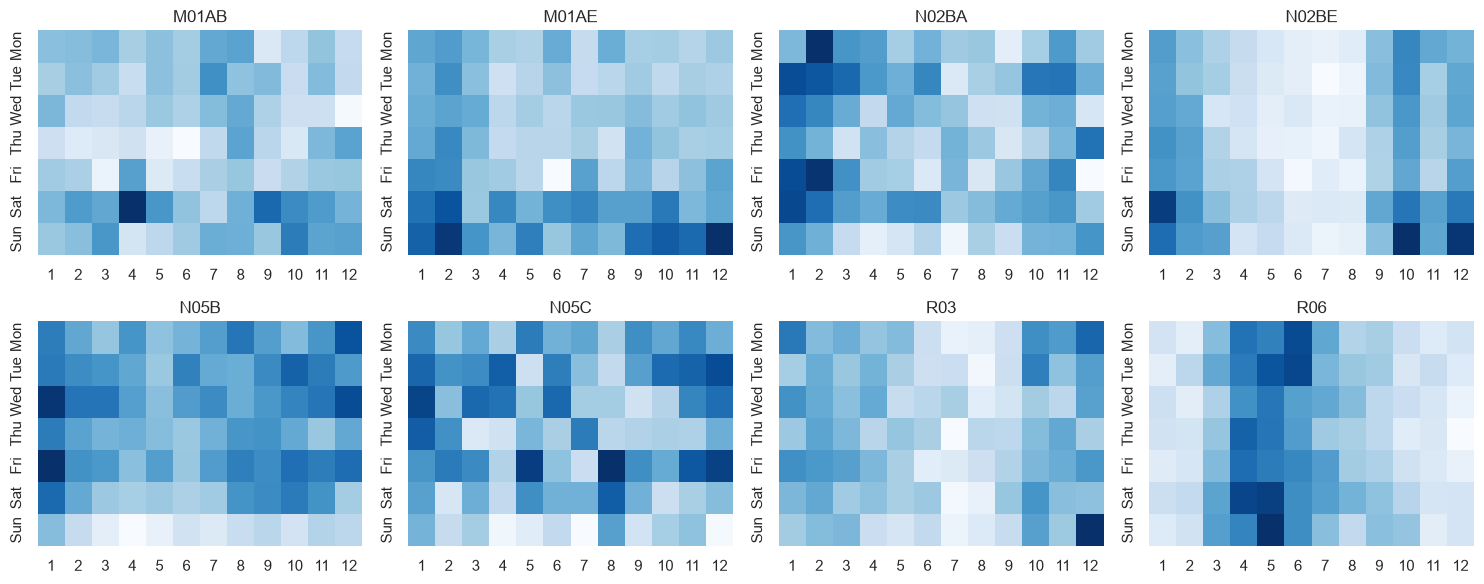

In [10]:
d = daily.assign(weekday=daily.date.dt.dayofweek, month=daily.date.dt.month)
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), sorted(d.category.unique())):
    p = d[d.category == c].pivot_table(index="weekday", columns="month", values="units", aggfunc="mean")
    p.index = order
    sns.heatmap(p, ax=ax, cmap="Blues", cbar=False); ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("")
savefig("eda_weekday_month_heatmaps")

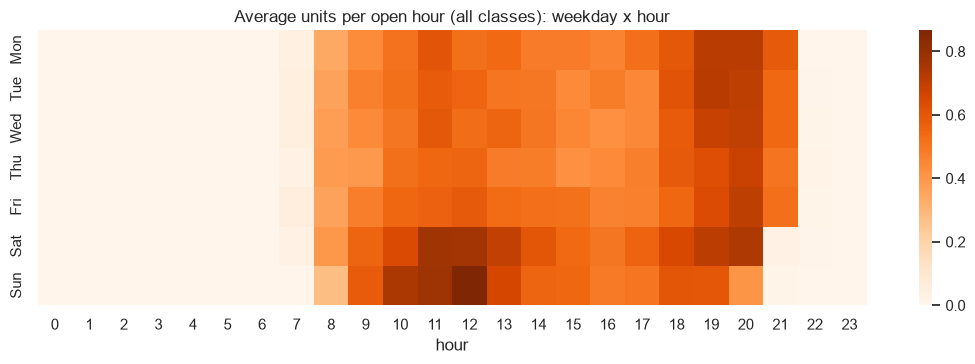

In [11]:
from src.data.store import read_hourly

h = read_hourly(cfg)
h = h.assign(weekday=h.date.dt.dayofweek, hour=h.date.dt.hour)
p = h.groupby(["weekday", "hour"])["units"].mean().unstack()
p.index = order
plt.figure(figsize=(11, 3.8)); sns.heatmap(p, cmap="Oranges")
plt.title("Average units per open hour (all classes): weekday x hour"); savefig("eda_weekday_hour_heatmap")

## 5. Correlation between classes

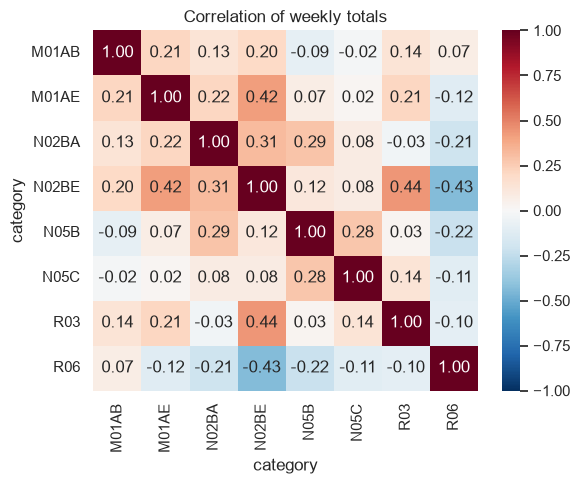

In [12]:
wk = piv.resample("W").sum().iloc[1:-1]
plt.figure(figsize=(6, 5)); sns.heatmap(wk.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation of weekly totals"); savefig("eda_correlation")

## 6. ABC (Pareto) and XYZ (variability) analysis
ABC uses revenue contribution (assumed prices); XYZ uses the coefficient of variation of *weekly* demand (daily CV is dominated by noise).

In [13]:
from src.analytics.descriptive import abc_xyz_matrix

mx = abc_xyz_matrix(daily, cfg)
mx[["category", "revenue", "share", "cum_share", "abc", "cv", "xyz", "class"]]

,category,revenue,share,cum_share,abc,cv,xyz,class
0,R03,"1,625,235.21",0.32,0.32,A,0.59,Z,AZ
1,N02BE,"1,134,097.25",0.22,0.54,A,0.36,Y,AY
2,N05B,"1,117,678.68",0.22,0.75,A,0.36,Y,AY
3,M01AE,"451,254.03",0.09,0.84,A,0.25,X,AX
4,M01AB,"371,032.80",0.07,0.91,B,0.24,X,BX
5,R06,"183,234.52",0.04,0.95,B,0.56,Z,BZ
6,N02BA,"179,788.60",0.03,0.98,B,0.29,X,BX
7,N05C,"92,938.63",0.02,1.00,C,0.73,Z,CZ


In [14]:
mx[["category", "class", "policy"]]

,category,class,policy
0,R03,AZ,"High value, erratic: tight monitoring, higher ..."
1,N02BE,AY,"High value, variable: forecast-driven replenis..."
2,N05B,AY,"High value, variable: forecast-driven replenis..."
3,M01AE,AX,"High value, stable: continuous review, lean sa..."
4,M01AB,BX,"Medium value, stable: periodic review with fix..."
5,R06,BZ,"Medium value, erratic: buffer stock with caps,..."
6,N02BA,BX,"Medium value, stable: periodic review with fix..."
7,N05C,CZ,"Low value, erratic: stock on request or small ..."


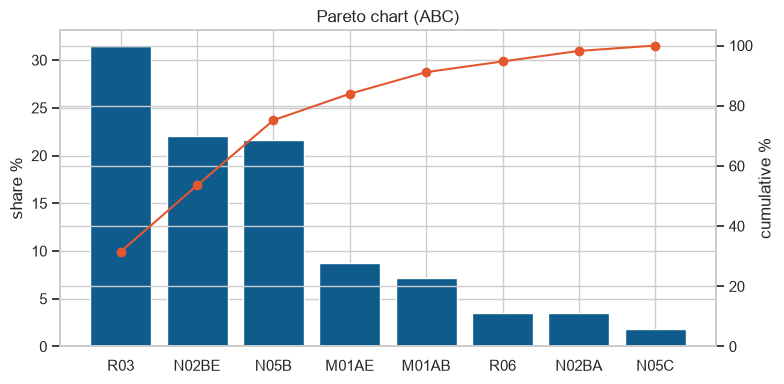

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(mx.category, mx.share * 100, color="#0F5C8C"); ax2 = ax.twinx()
ax2.plot(mx.category, mx.cum_share * 100, "o-", color="#E4572E"); ax2.set_ylim(0, 105)
ax.set_ylabel("share %"); ax2.set_ylabel("cumulative %"); ax.set_title("Pareto chart (ABC)")
savefig("eda_pareto")

## 7. Demand behaviour clusters
Behavioural features per class -> KMeans (k by silhouette) and Ward clustering, next to an interpretable rule-based label. With only 8 series this is exploratory.

In [16]:
cl = pd.read_csv(RES / "demand_clusters.csv")
cl[["category", "demand_label", "kmeans_cluster", "hier_cluster", "mean_daily", "cv_weekly", "zero_share",
    "weekly_seasonality", "annual_seasonality"]]

,category,demand_label,kmeans_cluster,hier_cluster,mean_daily,cv_weekly,zero_share,weekly_seasonality,annual_seasonality
0,M01AB,Fast-moving,1,0,5.03,0.24,0.02,0.22,0.05
1,M01AE,Slow-moving,1,0,3.90,0.25,0.02,0.21,0.08
2,N02BA,Slow-moving,1,0,3.88,0.29,0.04,0.22,0.10
3,N02BE,Seasonal,1,0,29.92,0.36,0.01,0.23,0.29
4,N05B,Fast-moving,1,0,8.85,0.36,0.02,0.23,0.11
5,N05C,Intermittent,2,2,0.59,0.73,0.68,0.05,0.15
6,R03,Seasonal & erratic,0,1,5.51,0.59,0.23,0.11,0.30
7,R06,Seasonal & erratic,0,1,2.90,0.56,0.12,0.14,0.45


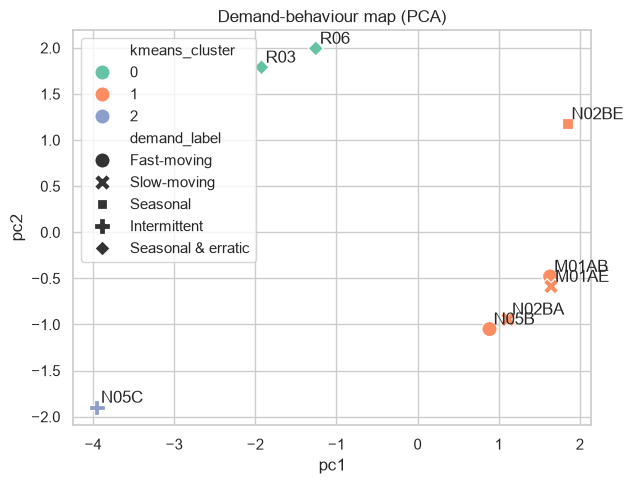

In [17]:
plt.figure(figsize=(6.5, 5))
sns.scatterplot(data=cl, x="pc1", y="pc2", hue="kmeans_cluster", style="demand_label", s=120, palette="Set2")
for r in cl.itertuples(): plt.text(r.pc1 + .05, r.pc2 + .05, r.category)
plt.title("Demand-behaviour map (PCA)"); savefig("eda_clusters")